In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
dir1 = os.path.dirname(os.path.abspath('..'))
if not dir1 in sys.path: sys.path.append(dir1)

In [2]:
from pathlib import Path
import pickle
import yaml
import pandas as pd
import numpy as np
import scipy.signal as ss

import seaborn as sns
from utils.plots import *
from utils.figures import plot_metrics
from utils.figures import print_stats
from matplotlib.gridspec import GridSpec

from utils import models

FIG = 'fig2'
config_fpath = Path(f'{FIG}.yml')
df_fpath = Path(f'{FIG}_df.csv')

In [3]:
data_dir = Path('../../experiments/simulation_base')
idx = '0001'

obs_fpath = data_dir / 'idx' / idx / f'{idx}_sig_obs.csv'
df_obs = pd.read_csv(obs_fpath)
t, y_obs = df_obs.t.values, df_obs.y.values

filt_fpath = data_dir / 'idx' / idx / 'filt' / f'{idx}_F_pyp.csv'
df_filt = pd.read_csv(filt_fpath)
t_filt, y_filt = df_filt.t.values, df_filt.y.values

bpd_fpath = data_dir / 'idx' / idx / 'filt' / f'{idx}_F_bpd.csv'
df_bpd = pd.read_csv(bpd_fpath)
t_bpd, y_bpd = df_bpd.t.values, df_bpd.y.values

sol_fpath = data_dir / 'idx' / idx / f'{idx}_soln_bpd.pkl'
with open(sol_fpath, 'rb') as f:
    bpd = pickle.load(f)

assert np.all(np.isclose(t, t_filt))
assert np.all(np.isclose(t, t_bpd))
fs = (t.size-1)/(t.max() - t.min())

true_fpath = data_dir / 'idx' / idx / f'{idx}_soln_true.pkl'
with open(true_fpath, 'rb') as f:
    true = pickle.load(f)
y_true = models.evaluate(t, true['z'], true['w'], true['f_h'], true['g'])[0]


In [4]:
def aligned(sig):
    sig = sig.copy()
    sig -= y_bpd.mean()
    sig *= y_true.std() / y_bpd.std()
    sig += y_true.mean()
    return sig

y_filt = aligned(y_filt)
y_bpd = aligned(y_bpd)

In [5]:
pypon_fpath = data_dir / 'idx' / idx / 'time' / f'{idx}_F_pyp_T_pyp.on.csv'
df_zon = pd.read_csv(pypon_fpath)

pypu_fpath = data_dir / 'idx' / idx / 'time' / f'{idx}_F_pyp_T_pyp.u.csv'
df_zu = pd.read_csv(pypu_fpath)

pypa_fpath = data_dir / 'idx' / idx / 'time' / f'{idx}_F_pyp_T_pyp.a.csv'
df_za = pd.read_csv(pypa_fpath)

pypsp_fpath = data_dir / 'idx' / idx / 'time' / f'{idx}_F_pyp_T_pyp.sp.csv'
df_zsp = pd.read_csv(pypsp_fpath)

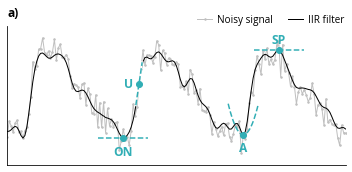

In [6]:

def subfigure_a(sub='a)'):
    ta, tb = 4.1, 6.8
    win = (t >= ta) & (t <= tb)
    ta, tb = t[win].min(), t[win].max()
    
    plt.plot(t[win], y_obs[win], '.-', c=cp[-1], markersize=3, zorder=-2, label='Noisy signal')
    plt.plot(t[win], y_filt[win], c='k', lw=1, label='IIR filter')

    label_font = {
        'fontweight': 'bold',
        'color': cp[3],
        'size': 12,
    }

    zon = df_zon.z.values
    zon = zon[np.argmin((zon-5.0)**2)]
    yon = np.interp(zon, t, y_filt)
    plt.scatter(zon, yon, c=cp[3], zorder=99)
    zz = np.linspace(zon-0.2, zon+0.2, 2)
    yy = np.full_like(zz, yon)
    plt.plot(zz, yy, '--', c=cp[3], lw=1.5)
    plt.text(zon, yon-y_filt.std()*0.25, 'ON',
             {'ha': 'center', 'va': 'top', **label_font})

    zu = df_zu.z.values
    zu = zu[np.argmin((zu-5.1)**2)]
    yu = np.interp(zu, t, y_filt)
    plt.scatter(zu, yu, c=cp[3], zorder=99)
    zz = np.linspace(zu-0.025, zu+0.025, 2)
    dydt = np.gradient(y_filt, 1/fs)
    yy = yu + (zz-zu) * np.interp(zu, t, dydt)
    plt.plot(zz, yy, '-', c='#FFFFFF', lw=2)
    plt.plot(zz, yy, '--', c=cp[3], lw=1.5)
    plt.text(zu-0.05, yu, 'U',
             {'ha': 'right', 'va': 'center', **label_font})

    za = df_za.z.values
    za = za[np.argmin((za-6.0)**2)]
    ya = np.interp(za, t, y_filt)
    plt.scatter(za, ya, c=cp[3], zorder=99)
    zz = np.linspace(za-0.12, za+0.12, 50)
    d2ydt2 = np.gradient(dydt, 1/fs)
    yy = ya + (zz-za)**2 * np.interp(za, t, d2ydt2)/10
    plt.plot(zz, yy, '--', c=cp[3], lw=1.5)
    plt.text(za, ya-y_filt.std()*0.25, 'A',
             {'ha': 'center', 'va': 'top', **label_font})

    zsp = df_zsp.z.values
    zsp = zsp[np.argmin((zsp-6.0)**2)]
    ysp = np.interp(zsp, t, y_filt)
    plt.scatter(zsp, ysp, c=cp[3], zorder=99)
    zz = np.linspace(zsp-0.2, zsp+0.2, 2)
    yy = np.full_like(zz, ysp)
    plt.plot(zz, yy, '--', c=cp[3], lw=1.5)
    plt.text(zsp, ysp+y_filt.std()*0.25, 'SP',
             {'ha': 'center', 'va': 'baseline', **label_font})

    plt.gca().set_ymargin(0.1)
    plt.yticks([])
    plt.xticks([])
    
    plt.legend(loc='lower right', bbox_to_anchor=(1, 1),
               ncol=3, columnspacing=1.5,
               frameon=False, borderpad=0.0, borderaxespad=0.1,
               handlelength=1.5, handletextpad=0.5)
    plt.title(sub, loc='left', pad=10, fontdict={'fontweight': 'bold'})


plt.figure(figsize=(5,2.5))
subfigure_a()
plt.show()


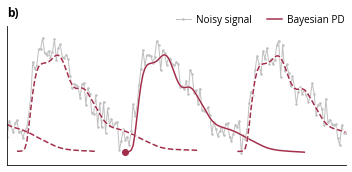

In [7]:
from utils import models

def subfigure_b(sub='b)'):
    ta, tb = 4.1, 6.8
    win = (t >= ta) & (t <= tb)
    ta, tb = t[win].min(), t[win].max()

    _, y_bpd = models.evaluate(
        t = t,
        z = bpd['z'],
        w = bpd['w'],
        f_h = bpd['f_h'],
        a = bpd.get('a'),
        b = bpd.get('b'),
        f_b = bpd.get('f_b'),
        g = bpd.get('g'),
    )

    plt.plot(t[win], y_obs[win], '.-', c=cp[-1], markersize=3, zorder=-2, label='Noisy signal')
    
    for zi in true['z']:
        if ta-1.0 < zi < tb:

            _, h_i = models.evaluate(
                t = t,
                z = [zi,],
                w = bpd['w'],
                f_h = bpd['f_h'],
                a = bpd.get('a'),
                b = bpd.get('b'),
                f_b = bpd.get('f_b'),
                g = bpd.get('g'),
            )
            h_i = np.array(h_i)

            h_i[(t<zi-0.05)|(t>zi+1.4)] = np.nan
            plt.plot(t[win], h_i[win], '-', c='#FFFFFF', lw=2)

            ls = '-' if (4.5 < zi < 5.5) else '--'
            label = 'Bayesian PD' if (4.5 < zi < 5.5) else None
            plt.plot(t[win], h_i[win], ls, c=cp[1], lw=1.5, label=label)
            
            tdot, hdot = t[np.argmax(~np.isnan(h_i))], h_i[np.argmax(~np.isnan(h_i))]
            if (4.5 < zi < 5.5):
                plt.scatter(tdot, hdot, c=cp[1], zorder=99)

    plt.gca().set_ymargin(0.1)
    plt.xticks([], [])
    plt.yticks([], [])
    plt.legend(loc='lower right', bbox_to_anchor=(1, 1),
               ncol=3, columnspacing=1.5,
               frameon=False, borderpad=0.0, borderaxespad=0.1,
               handlelength=1.5, handletextpad=0.5)
    plt.title(sub, loc='left', pad=10, fontdict={'fontweight': 'bold'})

plt.figure(figsize=(5,2.5))
subfigure_b()
plt.show()


median metrics:
method
F_ideal_T_pyp.u    0.006394
F_pyp_T_pyp.a      0.014451
F_pyp_T_pyp.on     0.030230
F_pyp_T_pyp.sp     0.028356
F_pyp_T_pyp.u      0.011981
T_bpd              0.004938
Name: zp_rmse, dtype: float64

	p=1.000E+00, PyPPG (SP) == PyPPG (ON)
***	p=5.579E-13, PyPPG (SP) <> PyPPG (U)
***	p=3.519E-04, PyPPG (SP) <> PyPPG (A)
***	p=2.203E-16, PyPPG (SP) <> Ideal Filter
***	p=5.845E-17, PyPPG (SP) <> Bayesian PD
***	p=9.647E-13, PyPPG (ON) <> PyPPG (U)
***	p=8.776E-05, PyPPG (ON) <> PyPPG (A)
***	p=2.070E-16, PyPPG (ON) <> Ideal Filter
***	p=5.845E-17, PyPPG (ON) <> Bayesian PD
***	p=7.436E-08, PyPPG (U) <> PyPPG (A)
***	p=3.991E-15, PyPPG (U) <> Ideal Filter
***	p=7.221E-17, PyPPG (U) <> Bayesian PD
***	p=4.556E-16, PyPPG (A) <> Ideal Filter
***	p=5.845E-17, PyPPG (A) <> Bayesian PD
***	p=1.056E-05, Ideal Filter <> Bayesian PD



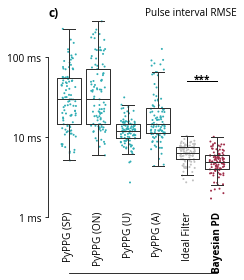

In [8]:
with open(config_fpath, 'r') as f:
    config = yaml.safe_load(f)
df = pd.read_csv(df_fpath)

y = config['y'][0]
metric = y['metric']
def subfigure_c(sub='c)', debug=False, stats=False):
    title = y['name']
    methods = [x['method'] for x in y['x']]
    names = [x['name'] for x in y['x']]
    df_temp = plot_metrics(df, metric, methods, names, log=True)
    
    plt.gca().set_xmargin(0.05)
    
    plt.gca().tick_params(axis="x", direction="in", pad=-62)
    plt.minorticks_off()
    plt.yticks([0.001, 0.01, 0.1, 1.0], ['1 ms', '10 ms', '100 ms', '1 s'])
    plt.ylim(0.0002, 0.3)
    sns.despine(ax=plt.gca(), bottom=(not debug), trim=True)
    labels = plt.gca().get_xticklabels()
    labels[-1].set_weight('bold')

    plt.title(sub, loc='left', pad=0, fontdict={'fontweight': 'bold'})
    plt.plot([np.nan], [np.nan], lw=0, label=title)
    plt.legend(loc='lower right', bbox_to_anchor=(1, 1),
               ncol=3, columnspacing=1.5,
               frameon=False, borderpad=0.0, borderaxespad=0.1,
               handlelength=1.0, handletextpad=0.5)
    
    star_y = 0.05
    plt.plot([4, 5], [star_y, star_y], c='k', lw=1)
    plt.text(4.5, star_y, '***', ha='center', fontdict={'fontweight':'bold'},)

    if stats:
        print_stats(df, metric, methods, names)

    return df_temp

plt.figure(figsize=(3.5,4))
df_temp = subfigure_c(debug=True, stats=True)
plt.show()


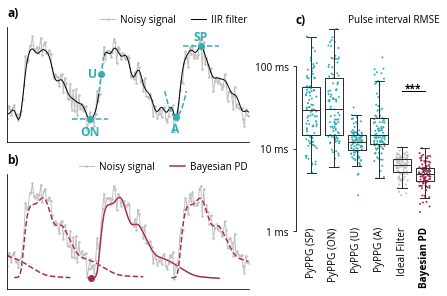

In [9]:
fig = plt.figure(figsize=(6.1,4), layout="constrained")

titlefont = {'fontweight':'bold'}
gs = GridSpec(2, 2, figure=fig,
              width_ratios=[5,3], height_ratios=[1, 1],
              wspace=0, hspace=0.03)
ax1 = fig.add_subplot(gs[0, 0])
subfigure_a()
ax2 = fig.add_subplot(gs[1, 0])
subfigure_b()
ax4 = fig.add_subplot(gs[:, 1])
subfigure_c()

plt.savefig(f'{FIG}.pdf', transparent=True)
plt.savefig(f'{FIG}.png', transparent=True, dpi=200)
plt.show()
